# PROYECTO FINAL TRIPLETEN CIENCIA DE DATOS
## PREDICCIÓN DE FUGA DE CLIENTES - INTERCONNECT

La empresa **Interconnect** quiere reducir la cancelación de clientes mediante un sistema que pueda anticipar que clientes podrían darse de baja, para ofrecerles promociones y planes especiales que garanticen su permanencia.

**Objetivo:** Desarrollar y comparar modelos predictivos que sean capaces de predecir si un cliente se dará de baja proximamente (Si/No). Las métricas principales de este proyecto serán AUC-ROC y Recall.

### Plan de trabajo

**0. Exploración de los datos.**
- Se revisará la información disponible en las bases de datos entregadas (número de datos, calidad de datos, duplicados, información ausente).
- Acondicionamiento y limpieza de datos.
  
**1. Definir variable objetivo y tipo de problema.**
- A partir del análisis exploratorio que se realice, se definirá el tipo de problema que debe resolver el modelo y sobre que variable específica se realizará.

**2. Preprocesamiento.**
- En esta parte, se hará el alistamiento de los datos: Conversión de tipo de dato, tratamiento de valores nulos o duplicados, evaluar balanceo de datos, etc.
- El objetivo en este punto es tener un archivo compacto y robusto que pueda entrar a la etapa de entrenamiento sin que vaya a arrojar errores en sus resultados o sesgos.
- Se formarán grupos de entrenamiento y prueba. Este último grupo será usado exclusivamente con el mejor modelo obtenido.

**3. Entrenamiento de modelos.**
- Se escogerán y entrenarán al menos 3 modelos distintos.
- Adicionalmente se debe tener un *Modelo Dummy* que sirva como base de comparación de resultados.
- Los modelos deben ser evaluados con métricas claras que sirvan al propósito del cliente y deben ir bien apoyadas con métricas secundarias que sustenten las decisiones.
- Se debe evaluar también temas como desbalance de datos, ajuste de hiperparámetros, umbrales de decisión.
- A partir de los mejores resultados obtenidos, se tomará solo un modelo para realizar la prueba con el conjunto separado en la etapa de preprocesamiento.
  
**4. Conclusiones.**
- Se incluiran los principales hallazgos de este estudio exploratorio y se determinará la validez o no del modelo seleccionado y probado.

### 0. Exploración de los datos (EDA)

In [1]:
# Carga librerías
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import roc_auc_score, recall_score, precision_score, f1_score, fbeta_score, confusion_matrix, roc_curve
from scipy.stats import loguniform
from lightgbm import LGBMClassifier

RANDOM_STATE = 792604

# Ignorar advertencias de Python
warnings.filterwarnings('ignore')
# Establecer visualización de grandes tablas
pd.set_option('display.max_columns', 50)


In [2]:
# Archivo 'contract.csv'
df_contract = pd.read_csv('/datasets/final_provider/contract.csv')
print('contract')
print(df_contract.info())
print()
print('Valores duplicados:', df_contract.duplicated().sum())
df_contract.head()

contract
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   BeginDate         7043 non-null   object 
 2   EndDate           7043 non-null   object 
 3   Type              7043 non-null   object 
 4   PaperlessBilling  7043 non-null   object 
 5   PaymentMethod     7043 non-null   object 
 6   MonthlyCharges    7043 non-null   float64
 7   TotalCharges      7043 non-null   object 
dtypes: float64(1), object(7)
memory usage: 440.3+ KB
None

Valores duplicados: 0


,customerID,BeginDate,EndDate,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,7590-VHVEG,2020-01-01,No,Month-to-month,Yes,Electronic check,29.85,29.85
1,5575-GNVDE,2017-04-01,No,One year,No,Mailed check,56.95,1889.5
2,3668-QPYBK,2019-10-01,2019-12-01 00:00:00,Month-to-month,Yes,Mailed check,53.85,108.15
3,7795-CFOCW,2016-05-01,No,One year,No,Bank transfer (automatic),42.30,1840.75
4,9237-HQITU,2019-09-01,2019-11-01 00:00:00,Month-to-month,Yes,Electronic check,70.70,151.65


#### Observaciones
- El archivo *contract* tiene 7043 registros y 8 columnas de los datos de los contratos de los usuarios.
- No se observan valores nulos ni duplicados.
- Tentativamente se deberían cambiar el tipo de datos de la columna 'BeginDate' a formato fecha y la columna ' TotalCharges' debe analizarse para determinar por que no aparece como datos de número sino como 'object'

In [3]:
# Archivo 'personal.csv'
df_personal = pd.read_csv('/datasets/final_provider/personal.csv')
print('personal')
print(df_personal.info())
print()
print('Valores duplicados:', df_personal.duplicated().sum())
df_personal.head()

personal
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   customerID     7043 non-null   object
 1   gender         7043 non-null   object
 2   SeniorCitizen  7043 non-null   int64 
 3   Partner        7043 non-null   object
 4   Dependents     7043 non-null   object
dtypes: int64(1), object(4)
memory usage: 275.2+ KB
None

Valores duplicados: 0


,customerID,gender,SeniorCitizen,Partner,Dependents
0,7590-VHVEG,Female,0,Yes,No
1,5575-GNVDE,Male,0,No,No
2,3668-QPYBK,Male,0,No,No
3,7795-CFOCW,Male,0,No,No
4,9237-HQITU,Female,0,No,No


#### Observaciones
- El archivo *personal* tambien posee 7043 registros y 5 columnas con los datos personales básicos de cada cliente.
- No se identifican valores nulos ni duplicados.
- No se observa algún pretratamiento adicional.

In [4]:
# Archivo 'internet.csv'
df_internet = pd.read_csv('/datasets/final_provider/internet.csv')
print('internet')
print(df_internet.info())
print()
print('Valores duplicados:', df_internet.duplicated().sum())
df_internet.head()

internet
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5517 entries, 0 to 5516
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   customerID        5517 non-null   object
 1   InternetService   5517 non-null   object
 2   OnlineSecurity    5517 non-null   object
 3   OnlineBackup      5517 non-null   object
 4   DeviceProtection  5517 non-null   object
 5   TechSupport       5517 non-null   object
 6   StreamingTV       5517 non-null   object
 7   StreamingMovies   5517 non-null   object
dtypes: object(8)
memory usage: 344.9+ KB
None

Valores duplicados: 0


,customerID,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies
0,7590-VHVEG,DSL,No,Yes,No,No,No,No
1,5575-GNVDE,DSL,Yes,No,Yes,No,No,No
2,3668-QPYBK,DSL,Yes,Yes,No,No,No,No
3,7795-CFOCW,DSL,Yes,No,Yes,Yes,No,No
4,9237-HQITU,Fiber optic,No,No,No,No,No,No



#### Observaciones
- El archivo *internet* esta compuesto por 5517 registros y 8 columnas con la información sobre el servicio de internet de los usuarios que tienen plan con **Interconnect**.
- No se identifican valores nulos ni duplicados.
- No se observa quye se requiera algún pretratamiento adicional. Los datos son basicamente categóricos.


In [5]:
# Archivo 'phone.csv'
df_phone = pd.read_csv('/datasets/final_provider/phone.csv')
print('phone')
print(df_phone.info())
print()
print('Valores duplicados:', df_phone.duplicated().sum())
df_phone.head()

phone
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6361 entries, 0 to 6360
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   customerID     6361 non-null   object
 1   MultipleLines  6361 non-null   object
dtypes: object(2)
memory usage: 99.5+ KB
None

Valores duplicados: 0


,customerID,MultipleLines
0,5575-GNVDE,No
1,3668-QPYBK,No
2,9237-HQITU,No
3,9305-CDSKC,Yes
4,1452-KIOVK,Yes


#### Observaciones
- Finalmente, el archivo *phone* se compone de 6361 registros y 2 columnas con los datos de estado de multiples líneas que tienen los usuarios.
- No se identifican valores nulos ni duplicados.
- No se determina un pretratamiento previo sobre estos datos.

In [6]:
# Tabla resumen
tabla = {'contract': df_contract, 'personal': df_personal, 'internet': df_internet, 'phone': df_phone}

resumen = pd.DataFrame({'filas': {n: t.shape[0] for n, t in tabla.items()},
                        'columnas': {n: t.shape[1] for n, t in tabla.items()},
                        'clientes únicos': {n: t['customerID'].nunique() for n, t in tabla.items()},
                        'IDs duplicados': {n: t['customerID'].duplicated().sum() for n, t in tabla.items()},
                        'valores nulos': {n: int(t.isna().sum().sum()) for n, t in tabla.items()}})
resumen

,filas,columnas,clientes únicos,IDs duplicados,valores nulos
contract,7043,8,7043,0,0
personal,7043,5,7043,0,0
internet,5517,8,5517,0,0
phone,6361,2,6361,0,0


#### Observaciones
Esta celda de resumen básicamente resume el código que se establece en las celdas previas ya que muestra los archivos con su número de registros y columnas así como la presencia de datos duplicados y nulos. 

En un caso como data scientist, las celdas iniciales me sirven como punto de arranque, pero al momento de hacer la entrega, puedo trabajar con esta última celda que transmite la misma información.

In [7]:
# Determinación de clientes por servicio
ids_internet = set(df_internet['customerID'])
ids_phone = set(df_phone['customerID'])
ids_all = set(df_contract['customerID'])

print('Clientes con contrato: ', len(ids_all))
print('Clientes con servicio de internet: ', len(ids_internet), '| Clientes con servicio de teléfono: ', len(ids_phone))
print('Clientes con solo servicio de internet: ', len(ids_internet - ids_phone))
print('Clientes con solo servicio de teléfono: ', len(ids_phone - ids_internet))
print('Clientes con ambos servicios: ', len(ids_internet & ids_phone))
print('Clientes con ningún servicio: ', len(ids_all - ids_internet - ids_phone))
print('Clientes que no aparezcan en contrato: ', len((ids_internet | ids_phone) - ids_all))

Clientes con contrato:  7043
Clientes con servicio de internet:  5517 | Clientes con servicio de teléfono:  6361
Clientes con solo servicio de internet:  682
Clientes con solo servicio de teléfono:  1526
Clientes con ambos servicios:  4835
Clientes con ningún servicio:  0
Clientes que no aparezcan en contrato:  0


#### Observaciones
- Se aprovecha que todos los archivos comparten la columna 'customerID' para evaluar que no se evidencien valores de ID ausentes en los otros juegos de datos.
- Se encuentran *7043 usuarios*, de los cuales *4835 usuarios* tiene planes compartidos de internet y teléfono, *682 usuarios* solo tienen servicio de internet y *1526 usuarios* tienen solo servicio de teléfono.
- No se encuentran usuarios que no tengan ninguno de los dos servicios o usuarios que esten en alguna base de datos y no en la base de datos *contract*.

*Este análisis nos permite proponer la fusión de las bases de datos en una sola para cuando se formulen los modelos predictivos.*

In [8]:
# Definición estado actual del contrato de los usuarios
print(df_contract['EndDate'].value_counts())
print()
print('Rango de tiempo de inicio de contrato')
print(df_contract['BeginDate'].min(), '-', df_contract['BeginDate'].max())
print()
date_end = df_contract.loc[df_contract['EndDate'] != 'No', 'EndDate']
print('Rango de tiempo de finalización de contrato')
print(date_end.min(), '-', date_end.max())
print()
print('Usuarios que ya no son clientes')
print(len(date_end))
print(f"{len(date_end)/len(ids_all)*100:.2f}%")

No                     5174
2019-11-01 00:00:00     485
2019-12-01 00:00:00     466
2020-01-01 00:00:00     460
2019-10-01 00:00:00     458
Name: EndDate, dtype: int64

Rango de tiempo de inicio de contrato
2013-10-01 - 2020-02-01

Rango de tiempo de finalización de contrato
2019-10-01 00:00:00 - 2020-01-01 00:00:00

Usuarios que ya no son clientes
1869
26.54%


#### Observaciones
- De la base de datos de contratos de la empresa **Interconnect** se encuentra que actualmente 1869 usuarios ya no tienen servicio contratado con la empresa. Esto representa el 26.5% del total de datos disponibles.
- La salida de usuarios aparece en el rango de tiempo de primero de octubre de 2019 a 1 de enero de 2020.


In [9]:
# Análisis de columna 'TotalCharges' en df_contract
print('Tipo de datos en TotalCharges: ', df_contract['TotalCharges'].dtype)
empty_obs = df_contract[df_contract['TotalCharges'].astype(str).str.strip() == '']
print('Número de registros vacios en TotalCharges:', len(empty_obs))
empty_obs

Tipo de datos en TotalCharges:  object
Número de registros vacios en TotalCharges: 11


,customerID,BeginDate,EndDate,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
488,4472-LVYGI,2020-02-01,No,Two year,Yes,Bank transfer (automatic),52.55,
753,3115-CZMZD,2020-02-01,No,Two year,No,Mailed check,20.25,
936,5709-LVOEQ,2020-02-01,No,Two year,No,Mailed check,80.85,
1082,4367-NUYAO,2020-02-01,No,Two year,No,Mailed check,25.75,
1340,1371-DWPAZ,2020-02-01,No,Two year,No,Credit card (automatic),56.05,
3331,7644-OMVMY,2020-02-01,No,Two year,No,Mailed check,19.85,
3826,3213-VVOLG,2020-02-01,No,Two year,No,Mailed check,25.35,
4380,2520-SGTTA,2020-02-01,No,Two year,No,Mailed check,20.00,
5218,2923-ARZLG,2020-02-01,No,One year,Yes,Mailed check,19.70,
6670,4075-WKNIU,2020-02-01,No,Two year,No,Mailed check,73.35,


#### Observaciones
Se analizan los datos de la columna 'TotalCharges' del set df_contract, encontrando lo siguiente:
- Se encuentran 11 observaciones donde no se encuentra un dato o valor en 'TotalCharges'.
- Estos 11 datos coinciden con algo: tienen fecha de inicio de contrato 2020-02-01 y siguen activos.
- Lo anterior indica que son nuevos clientes y aún no se les ha facturado cuenta.
- Este análisis permite identificar que esta columna aparece como formato *object* pero puede convertirse en número cuando deba hacerse el preprocesamiento de datos, dejando estos datos faltantes en '0'.

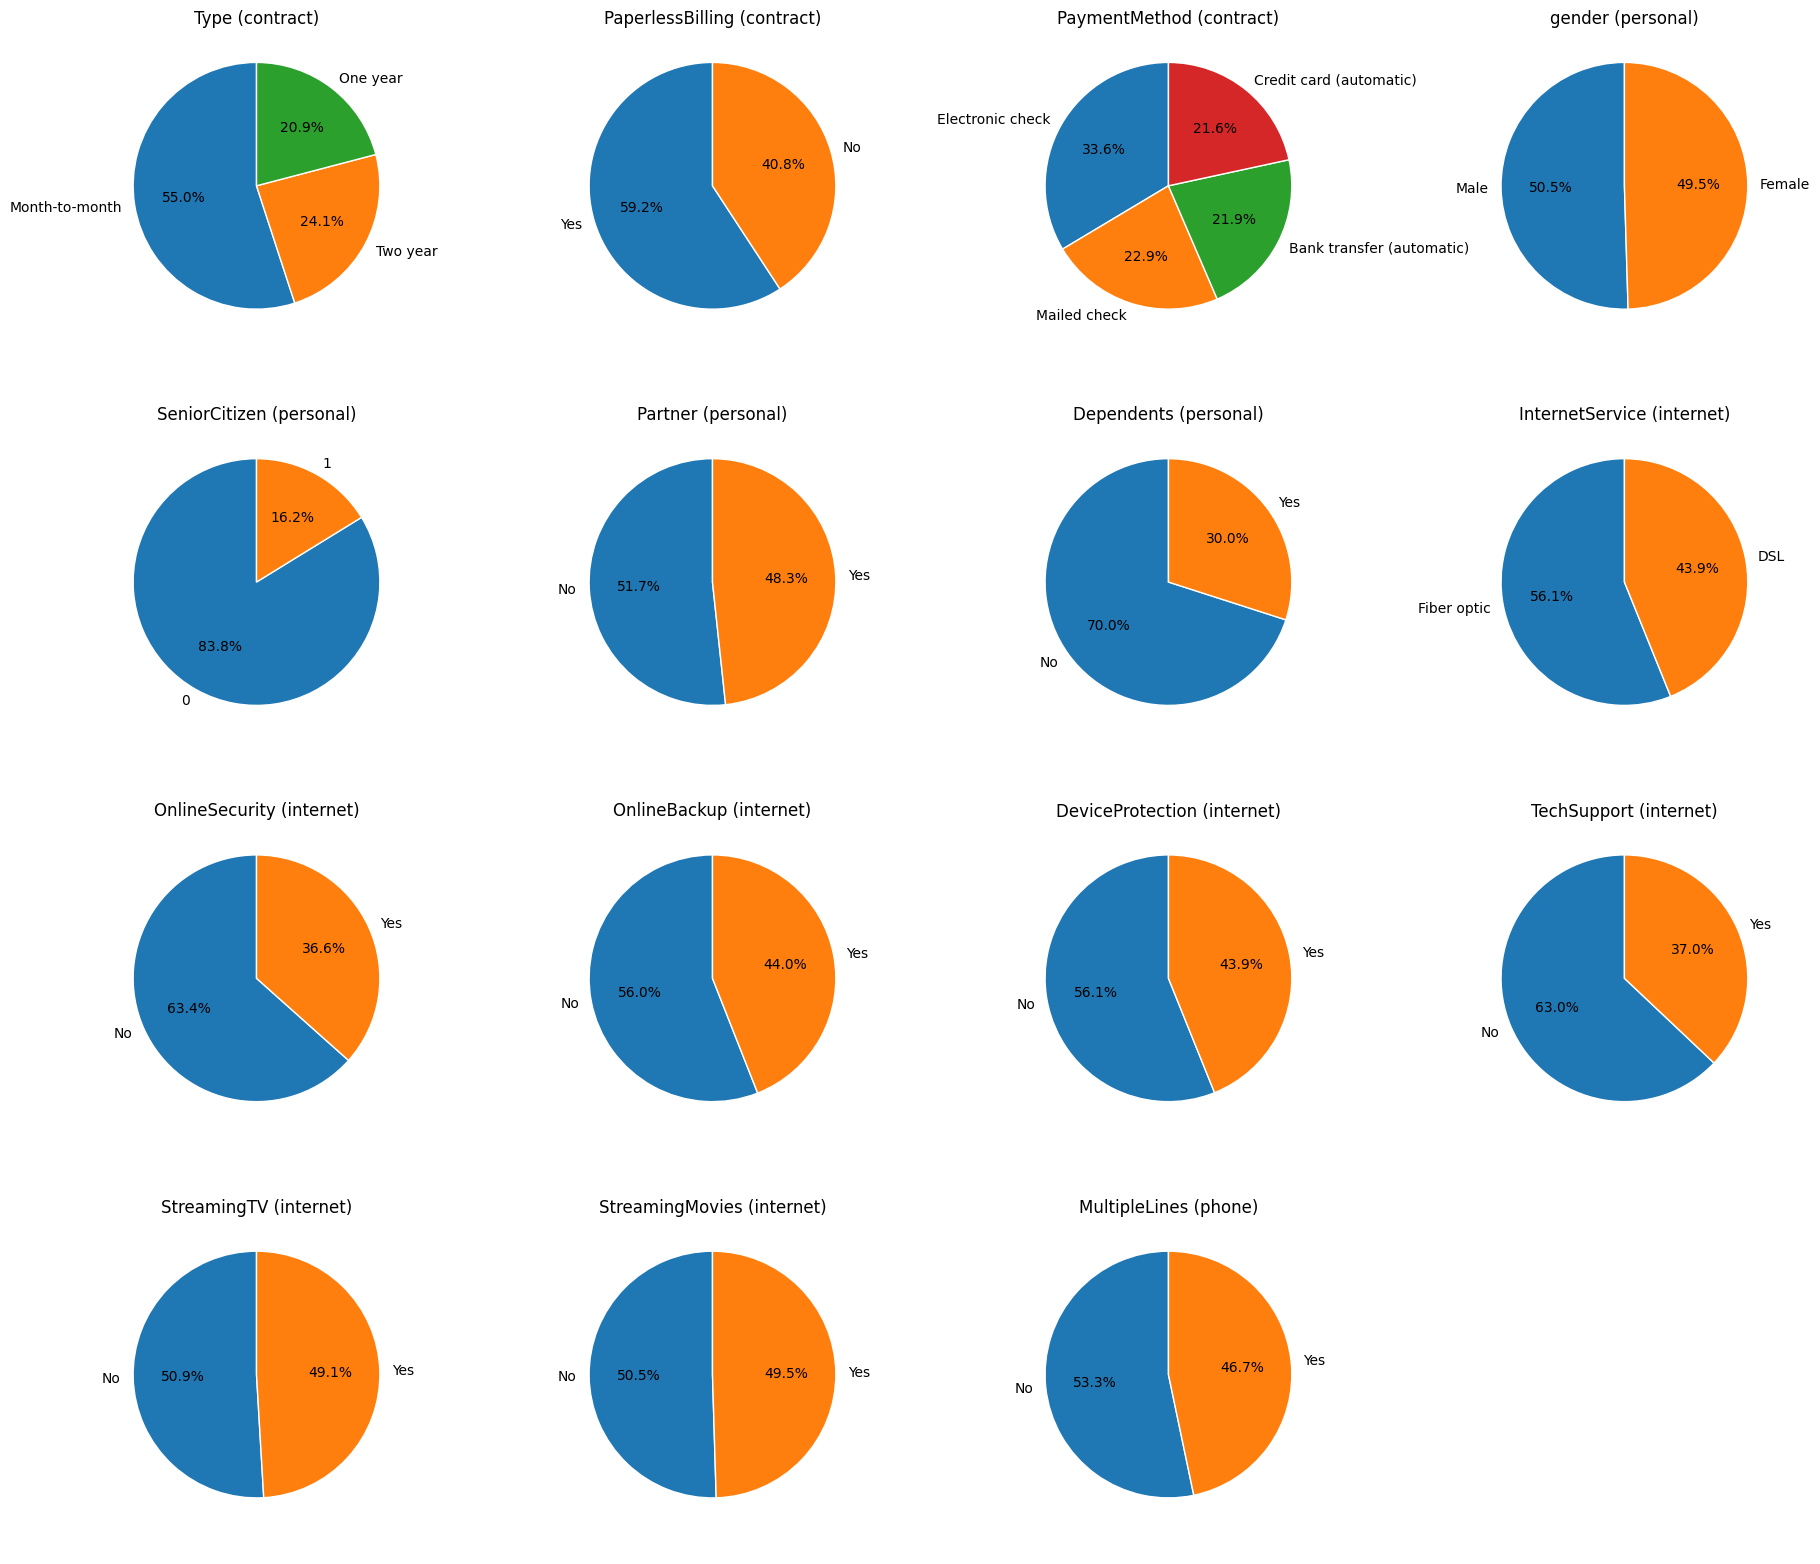

In [10]:
# Distribución estadística variables categóricas
cat_cols = {
    'contract': ['Type', 'PaperlessBilling', 'PaymentMethod'],
    'personal': ['gender', 'SeniorCitizen', 'Partner', 'Dependents'],
    'internet': ['InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
                   'TechSupport', 'StreamingTV', 'StreamingMovies'],
    'phone': ['MultipleLines']
}

# Lista plana de variables categóricas
variables = [(name, col) for name, cols in cat_cols.items() for col in cols]

# Creación matriz de gráficos
n_cols = 4
n_filas = math.ceil(len(variables) / n_cols)
fig, axes = plt.subplots(n_filas, n_cols, figsize=(4.5*n_cols, 4*n_filas))
axes = axes.flatten()

for ax, (name, col) in zip(axes, variables):
    count = tabla[name][col].value_counts()
    ax.pie(count, labels=count.index, autopct='%1.1f%%', startangle=90,
          wedgeprops={'edgecolor': 'white'})
    ax.set_title(f'{col} ({name})')

for ax in axes[len(variables):]:
    ax.axis('off')

plt.tight_layout()
plt.show()

#### Observaciones
- Se realiza un análisis estadístico a todas las variables categóricas que se tienen disponibles. Esto permite conocer un poco mas de los usuarios y el tipo de cuentas que manejan:
- De acuerdo con el tipo de contrato, **55% de los usuarios manejan un contrato mensual**, 20.9% un contrato anual y un 24.1% de los usuarios manejan un contrato a 2 años. *Esto será de utilidad al momento de desarrollar los modelos*.
- **59.2% de los usuarios manejan facturación sin papel**, el 40.8% restante si usa papel.
- **33.6% de los usuarios paga por medio de cheque electrónico**, 22.9% envia cheque por correo, y por medio de debito automático se maneja un 21.6% que paga con su tarjeta de crédito y 21.9% por transferencia bancaria. *Este dato también podría ser de utilidad en el desarrollo del modelo*.
- **83.8% de los usuarios no son adultos mayores** comparado con un 16.2% que si lo es.
- Se tiene una **paridad estadística** en los campos de género del usuario, si tiene o no pareja, por el tipo de servicio de internet que tiene (fibra óptica o DSL), si maneja o no un backup  online, si cuenta o no con protección del equipo, si maneja o no streaming de TV o de películas, y si tiene varias líneas de teléfono. *Esto muestra un balance de los datos al momento de realizar las predicciones*.
- **70% de los usuarios tiene personal dependiente**, 30% no lo tiene.
- Finalmente **aproximadamente 63% de los usuarios cuentan con servicio de seguridad online y soporte técnico**.

**Este análisis estadístico nos da ideas de posibles sesgos y desbalances al momento de realizar el modelado.**

In [11]:
# Análisis estadístico variable numérica
df_contract['MonthlyCharges'].describe().round(2)

count    7043.00
mean       64.76
std        30.09
min        18.25
25%        35.50
50%        70.35
75%        89.85
max       118.75
Name: MonthlyCharges, dtype: float64

#### Observaciones
- **En promedio, se facturan $64.76 mensualmente por usuario**.
- La factura más económica es de *$18.25* y la más costosa es de *$118.75*.
- *La desviación estándar de estos costos cargados mensualmente es de 30.09*. Esto muestra gran dispersión de la facturación y podrá ser sensible al momento de realizar modelado, también será de utilidad para el grupo de marketing cuando realice planes de fidelización.

### 1. Definir variable objetivo y tipo de problema

Basado en la revisión de los datos, y de acuerdo con la necesidad del cliente, Se debe generar una variable **Churn** que describa la finalización o abandono del servicio por parte del usuario. Esta variable se deriva de la columna 'EndDate' de df_contract.

Este será un **problema de clasificación binaria (deja el servicio o no)**, en gran parte a partir de variables categóricas, las cuales podrán tener una codificación OHE sin generar un modelo de muchas categorías ya que dichas variables tienen entre 2 y 4 posibilidades.

Dado que se tienen datos de un 26% de abandono de los clientes, se identifica un **desbalance de clases en esta categoría** que se debe tener en cuenta. Las variables categóricas en general se encuentran relativamente balanceadas.

Las métricas para evaluar el modelo serán el **ROC-AUC** como métrica principal y el *Recall* como una métrica secundaria auxiliar. Todos los juegos de datos se pueden fusionar teniendo en cuenta que se comparte la columna 'CustomerID', donde se tendrá que manejar especial cuidado en los casos donde el usuario tenga un solo servicio.

### 2. Preprocesamiento

In [12]:
# Unión de los juegos de datos
df = (df_contract
     .merge(df_personal, on='customerID', how='left')
     .merge(df_internet, on='customerID', how='left')
     .merge(df_phone, on='customerID', how='left'))

print(df.shape)
print()

# Determinación y manejo valores nulos tras la fusión de datos
internet_cols = ['InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
                'TechSupport', 'StreamingTV', 'StreamingMovies']
print('Valores nulos luego de la unión')
print(df[internet_cols + ['MultipleLines']].isna().sum())

(7043, 20)

Valores nulos luego de la unión
InternetService     1526
OnlineSecurity      1526
OnlineBackup        1526
DeviceProtection    1526
TechSupport         1526
StreamingTV         1526
StreamingMovies     1526
MultipleLines        682
dtype: int64


#### Observaciones
- Se unen los 4 juegos de datos disponibles a partir de la columna 'customerID'.
- Luego de la fusión de datos, aparecen como valores nulos *682 observaciones* de personas que tienen solo internet y no teléfono y *1526 usuarios* que tienen solo teléfono y no internet.
- Para el modelado se podrá rellenar los valores nulos asi: **'Sin internet'** ó **'Sin telefonía'**, según sea el caso.

In [13]:
# Tratamiento valores nulos
df[internet_cols] = df[internet_cols].fillna('Sin Internet')
df['MultipleLines'] = df['MultipleLines'].fillna('Sin telefonía')

# Revisión
print('Valores nulos luego del tratamiento:')
print(df[internet_cols + ['MultipleLines']].isna().sum().sum())

df['MultipleLines'].value_counts()

Valores nulos luego del tratamiento:
0


No               3390
Yes              2971
Sin telefonía     682
Name: MultipleLines, dtype: int64

In [14]:
# Definición variable objetivo: 1 = El cliente se dio de baja, 0 = El cliente contínua
df['churn'] = (df['EndDate'] != 'No').astype(int)

print(df['churn'].value_counts())
print('Porcentaje de fuga: ', round(df['churn'].mean()*100, 4))

0    5174
1    1869
Name: churn, dtype: int64
Porcentaje de fuga:  26.537


#### Observaciones
- Se unen los 4 juegos de datos y se crea la categoría 'churn' como variable objetivo.
- Se corrobora que se mantenga el porcentaje de abandono de la compañía en 26.54%.

In [15]:
# Cambio en 'BeginDate' y 'EndDate' a tipo fecha
df['BeginDate'] = pd.to_datetime(df['BeginDate'])
df['EndDate_dt'] = pd.to_datetime(df['EndDate'], errors='coerce')

# Determinación de fecha de corte estudio
fecha_corte = df['BeginDate'].max()
print('Fecha de corte: ', fecha_corte.date())

# Determinación de antiguedad de los usuarios
df['dias_cliente'] = (df['EndDate_dt'].fillna(fecha_corte) - df['BeginDate']).dt.days

# Rellenar 'TotalCharges' ausentes con 0
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].astype(str).str.strip(), errors='coerce').fillna(0)

df.head()

Fecha de corte:  2020-02-01


,customerID,BeginDate,EndDate,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,gender,SeniorCitizen,Partner,Dependents,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,MultipleLines,churn,EndDate_dt,dias_cliente
0,7590-VHVEG,2020-01-01,No,Month-to-month,Yes,Electronic check,29.85,29.85,Female,0,Yes,No,DSL,No,Yes,No,No,No,No,Sin telefonía,0,NaT,31
1,5575-GNVDE,2017-04-01,No,One year,No,Mailed check,56.95,1889.50,Male,0,No,No,DSL,Yes,No,Yes,No,No,No,No,0,NaT,1036
2,3668-QPYBK,2019-10-01,2019-12-01 00:00:00,Month-to-month,Yes,Mailed check,53.85,108.15,Male,0,No,No,DSL,Yes,Yes,No,No,No,No,No,1,2019-12-01,61
3,7795-CFOCW,2016-05-01,No,One year,No,Bank transfer (automatic),42.30,1840.75,Male,0,No,No,DSL,Yes,No,Yes,Yes,No,No,Sin telefonía,0,NaT,1371
4,9237-HQITU,2019-09-01,2019-11-01 00:00:00,Month-to-month,Yes,Electronic check,70.70,151.65,Female,0,No,No,Fiber optic,No,No,No,No,No,No,No,1,2019-11-01,61


In [16]:
# Estudio servicios adicionales de internet
extra_services = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
                 'TechSupport', 'StreamingTV', 'StreamingMovies']

# Usarios con internet (1=si, 0=no)
df['tiene_internet'] = (df['InternetService'] != 'Sin Internet').astype(int)
# Usarios con teléfono (1=si, 0=no)
df['tiene_telefono'] = (df['MultipleLines'] != 'Sin telefonía').astype(int)
# Usuarios con servicios extra
df['n_servicios_extra'] = (df[extra_services] == 'Yes').sum(axis=1)

df[['tiene_internet', 'tiene_telefono', 'n_servicios_extra']].describe().round(2)

,tiene_internet,tiene_telefono,n_servicios_extra
count,7043.00,7043.0,7043.00
mean,0.78,0.9,2.04
std,0.41,0.3,1.85
min,0.00,0.0,0.00
25%,1.00,1.0,0.00
50%,1.00,1.0,2.00
75%,1.00,1.0,3.00
max,1.00,1.0,6.00


#### Observaciones
- Se continua el preprocesamiento de los datos antes de iniciar el modelamiento. Se generan 3 columnas para determinar los clientes que tienen servicios de internet, servicios de telefonía y cuantos servicios adicionales de internet tienen contratados.
- Se corrobora que aproximadamente *78% de los usuarios tienen servicio de internet* y *90% de los usuarios servicio de telefonía*.
- En promedio, los usuarios contratan *2 servicios adicionales de internet*.

#### Evaluación del comportamiento de algunas características categóricas con la finalización del contrato

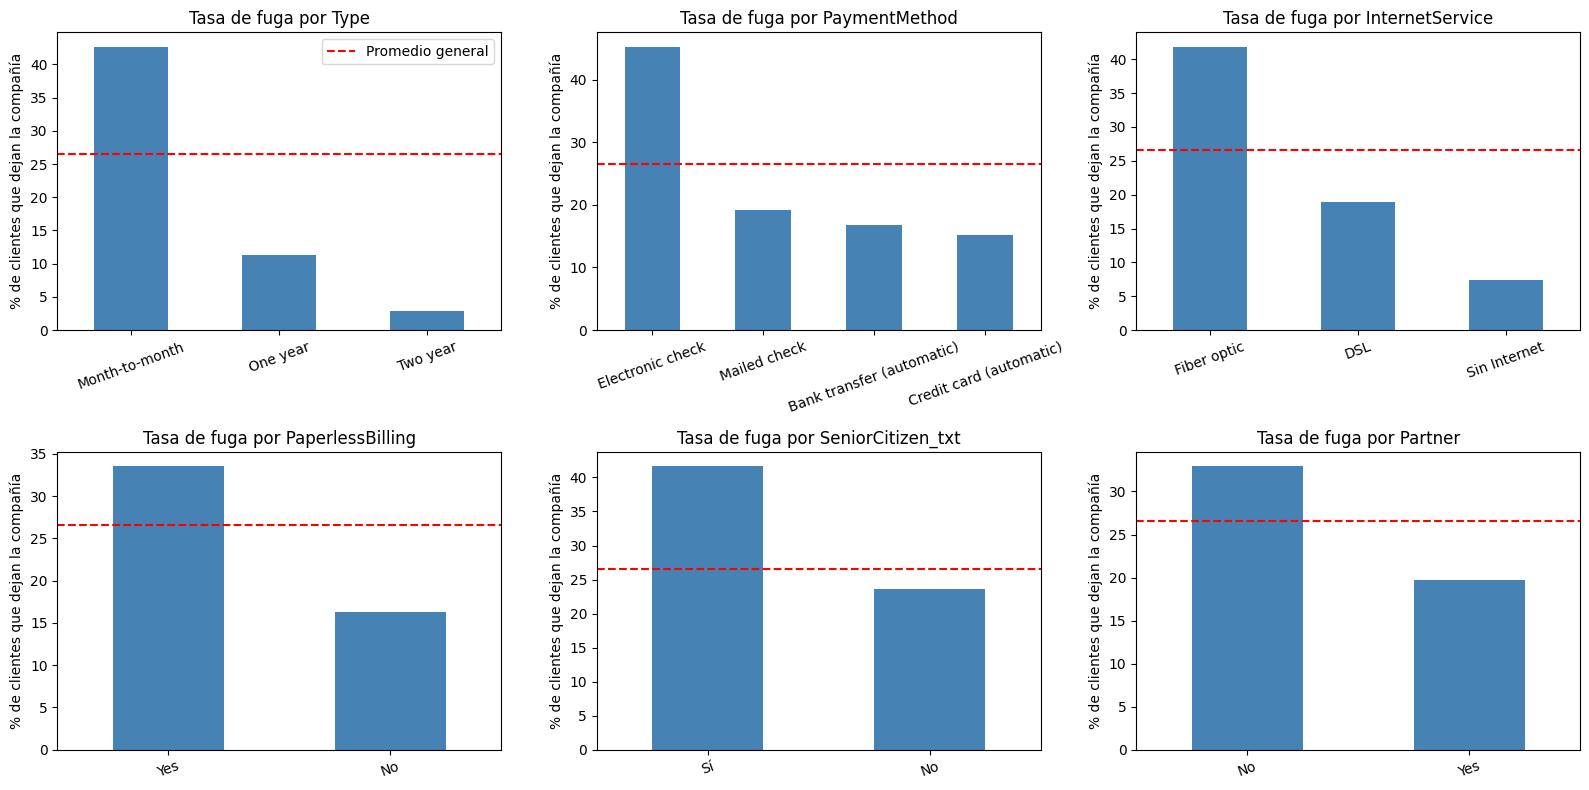

In [17]:
# Establecer términos para 'SeniorCitizen'
df['SeniorCitizen_txt'] = df['SeniorCitizen'].map({0: 'No', 1: 'Sí'})

# Definición columnas categóricas a evaluar
cat_graph = ['Type', 'PaymentMethod', 'InternetService', 'PaperlessBilling', 'SeniorCitizen_txt', 'Partner']

# Construcción del gráfico
fig, axes = plt.subplots(2, 3, figsize=(16,8))
for ax, col in zip(axes.ravel(), cat_graph):
    tasa = df.groupby(col)['churn'].mean().sort_values(ascending=False) * 100
    tasa.plot.bar(ax=ax, color='steelblue', label='_nolegend_')
    ax.axhline(df['churn'].mean() * 100, color='red', linestyle='--', label='Promedio general')
    ax.set_title(f'Tasa de fuga por {col}')
    ax.set_ylabel('% de clientes que dejan la compañía')
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=20)
axes[0, 0].legend()
plt.tight_layout()
plt.show()

#### Observaciones
El gráfico nos muestra observaciones muy interesantes. Teniendo una base del 26.54% de fuga de clientes:
- El tipo de contrato muestra que tan factible es que un usuario abandone la compañía. **Mas del 40% de los usuarios que cancelaron su contrato tenían un contrato mensual**, comparado con usuarios con contrato a 2 años, *el cual fue menor al 5%*.
- Con el método de pago sucede algo similar. **Aproximadamente un 45% de los usuarios que cancelaron su servicio manejaban un pago con cheque electrónico**. Los pagos automáticos tienen *una fuga cercana al 15%*, es decir, una tercera parte.
- Se evidencia **una cancelación aproximada al 40% en clientes que manejaban servicio de internet con fibra óptica**. Esto puede indicar *falencias en este servicio o un alto costo del servicio*.
- **La facturación sin papel tiene un porcentaje de fuga superior al 30%**. Esto también puede indicar problemas con la información de facturación.
- Hay **un porcentaje de abandono superior al 40% en usuarios que son adultos mayores** en comparación con algo menos del 25% que no lo son.
- Los **usuarios con pareja cancelan el servicio en un 35%** comparado con casi 20% de personal soltero que no lo hace.

**Estos valores serán de utilidad al departamento de fidelidad al momento de establecer campañas de fidelización**

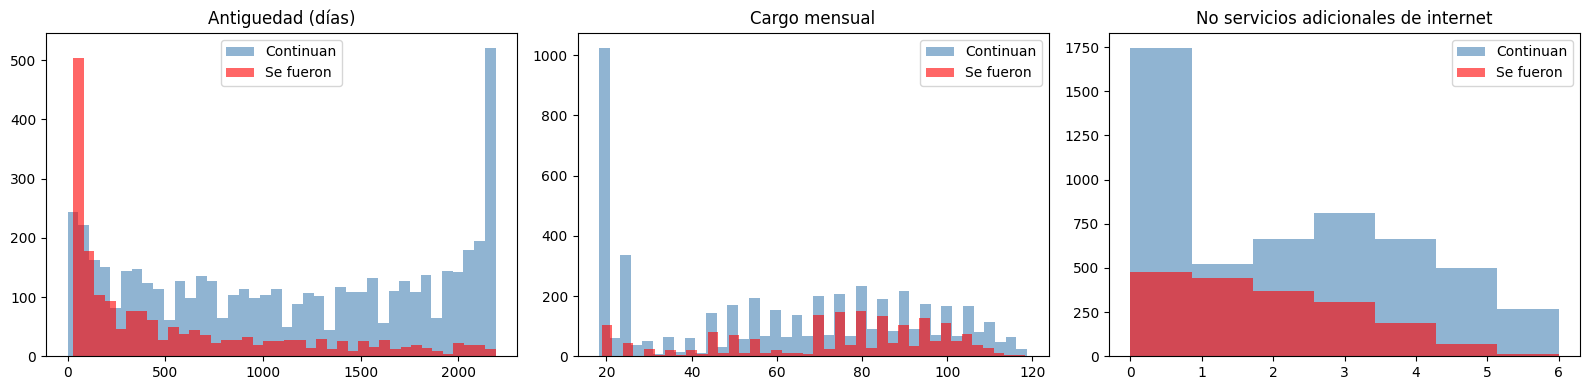

,dias_cliente,MonthlyCharges,TotalCharges,n_servicios_extra
churn,,,,
0,1144.4,61.3,2549.9,2.1
1,547.4,74.4,1531.8,1.8


In [18]:
# Comparación de permanencia de usuarios dependiendo de antiguedad, cargo mensual y servicios de internet adicionales
fig, axes = plt.subplots(1, 3, figsize=(16,4))

for value, label, color in [(0, 'Continuan', 'steelblue'), (1, 'Se fueron', 'red')]:
    subconj = df[df['churn'] == value]
    axes[0].hist(subconj['dias_cliente'], bins=40, alpha=0.6, label=label, color=color)
    axes[1].hist(subconj['MonthlyCharges'], bins=40, alpha=0.6, label=label, color=color)
    axes[2].hist(subconj['n_servicios_extra'], bins=7, alpha=0.6, label=label, color=color)

axes[0].set_title('Antiguedad (días)')
axes[1].set_title('Cargo mensual')
axes[2].set_title('No servicios adicionales de internet')

for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

# Tabla de promedios
df.groupby('churn')[['dias_cliente', 'MonthlyCharges', 'TotalCharges', 'n_servicios_extra']].mean().round(1)

#### Observaciones
- En promedio, los usuarios que cancelan el servicio tienen una **poca antiguedad con la compañía (547.4 días ~ 18 meses)** comparado con los que *siguen usando los servicios (1144.4 días ~ 38 meses)*. *Se identifica un pico de fuga muy alto en clientes con muy poca antiguedad, así como un pico alto de permanencia en usuarios con alta antiguedad*.
- La cancelación del servicio ocurre en promedio con **usuarios que pagan un poco más en su factura ($74.4)** en comparación con los usuarios que siguen con el servicio ($61.3).
- Inicialmente **no se observa una tendencia clara en el abandono del servicio relacionada con la cantidad de servicios de internet adicionales (aproximadamente 2)**. Sin embargo, del histograma se puede inferir que a medida que se tienen mas servicios adicionales, es menor la tasa de fuga. Se debe tener en cuenta la alta dispersión de estos datos encontrada previamente.
- El total pagado por los usuarios es una variable que debe evaluarse con cuidado. **Aparentemente permanecen los que en promedio han pagado mas, pero se debe tener en cuenta que son usuarios de alta antiguedad.**
- En general se puede concluir que **El abandono de los servicios en la empresa obedece en usuarios con poca antiguedad y alto costo de su facturación**. Esto puede tenerse en cuenta también en los usuarios que tienen servicio de internet por fibra óptica.
- No se identifica una linealidad clara en el comportamiento de las variables categóricas con la cancelación del servicio, **lo que puede favorecer modelos predictivos basados en árboles**.

#### Verificación de *data leakage*


In [19]:
# Variables definitivas para el modelo a partir de texto
text_cols = ['Type', 'PaperlessBilling', 'PaymentMethod', 'gender', 'Partner',
             'Dependents', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
             'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
             'MultipleLines']

# Función de construcción del dataset para modelamiento
def construir_X(datos, col_antiguedad, usar_total=True):
    X = datos.drop(columns=['customerID', 'BeginDate', 'EndDate', 'EndDate_dt', 'SeniorCitizen_txt',
                           'churn', 'dias_cliente', 'dias_hasta_corte'], errors='ignore')
    X['dias_cliente'] = datos[col_antiguedad]
    if not usar_total:
        X = X.drop(columns=['TotalCharges'])
    # Codificación OHE
    X = pd.get_dummies(X, columns=text_cols, drop_first=True).astype(float)
    # Reemplazo caracteres diferentes a letras o números por '_'
    X.columns = X.columns.str.replace(r'[^0-9a-zA-Z_]', '_', regex=True)
    return X

## Alternativa (con fuga): manejando antiguedad medida hasta la fecha de corte con todos los clientes
df['dias_hasta_corte'] = (fecha_corte - df['BeginDate']).dt.days

# Validación cruzada
cv_rapido = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
variantes = [('A) Antiguedad hasta EndDate (o hasta el corte), con TotalCharges', 'dias_cliente', True),
            ('B) Antiguedad hasta el corte para todos, con TotalCharges', 'dias_hasta_corte', True),
            ('C) Antiguedad hasta el corte para todos, SIN TotalCharges', 'dias_hasta_corte', False)]

for name, col, usar_total in variantes:
    X_tmp = construir_X(df, col, usar_total)
    auc = cross_validate(LGBMClassifier(random_state=RANDOM_STATE, n_jobs=1, verbose=-1),
                        X_tmp, df['churn'], cv=cv_rapido, scoring='roc_auc')['test_score'].mean()

    print(f'{name}: AUC = {auc:.4f}')


A) Antiguedad hasta EndDate (o hasta el corte), con TotalCharges: AUC = 0.9026
B) Antiguedad hasta el corte para todos, con TotalCharges: AUC = 0.9326
C) Antiguedad hasta el corte para todos, SIN TotalCharges: AUC = 0.8448


#### Observaciones
- Con una evaluación preliminar se encuentra que el *mejor valor de AUC se presenta en un modelo B, considerando la antiguedad hasta el corte aplicada para todos, incluyendo los cargos totales.* Sin embargo, Esto es una pista falsa. Bajo este modelo, se puede comparar lo facturado con lo esperado (*TotalCharges vs MonthlyCharges*) y de esta forma, determinar quien pudo terminar su contrato con Interconnect. Esta *data leakage* se confirma con el AUC del modelo C que no tiene en cuenta TotalCharges y da un valor bajo de 0.8448.
- **La versión A es la que debe tenerse en cuenta**, definir la antiguedad a partir de las fechas de inicio y final del contrato permitirá establecer la relación de *TotalCharges* con *MonthlyCharges x Antiguedad* en todos los clientes y podrá evitarse este sesgo.

### 3. Entrenamiento de los modelos

#### Codificación
- Como las categorías categóricas son nominales y con pocas opciones, **se realiza una codificación OHE con drop_first=True**.  Se elimina una característica por variable para evitar la redundancia en los modelos, y se obtendran finalmente pocas columnas para el modelo.
- En las características numéricas se hará un escalado con *StandardScaler* en la regresión logística evitando que los valores de unas variables dominen sobre otras.

#### Partición
- Se realizará una partición de **datos de entrenamiento de 75%** y de **datos de prueba del 25%**, estratificando 'churn' para conservar la proporción de fugas en ambos juegos de datos, permitiendo que las métricas finales sean comparables con las del entrenamiento.

#### Modelos
Se entrenarán 4 modelos *sin ninguna técnica de balanceo y con hiperparámetros por defecto:*
- Modelo Dummy (línea base)
- Regresión logística (dentro de un *Pipeline* que escale las variables y entrene el modelo, manejando 2000 iteraciones)
- Random Forest (de 200 árboles)
- LightGBM

Cada modelo se evaluará con **validación cruzada estratificada de 5 particiones sobre el conjuntos de datos de entrenamiento**.

Las métricas de evaluación del modelo serán **AUC-ROC** como valor principal, y **Recall** así como **Precisión** como métricas secundarias que apoyan y refuerzan los hallazgos.

#### Optimización y manejo del desbalance
- Se realizará un ajuste de pesos de clase (en **Regresión Logística** y **Random Forest** se aplica *class_weight='balanced'* y en **LightGBM** se aplica *is_unbalanced=True*) para mitigar el hecho de que se tiene un desbalance en los datos de los usuarios que cancelaron su servicio.
- Para optimizar el **AUC-ROC** se realiza una búsqueda de hiperpárametros con *RandomizedSearchCV

In [20]:
# Creación dataset
X = construir_X(df, 'dias_cliente')
y = df['churn']

# Formación conjuntos de entrenamiento y de prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y)

# Revisión características para el modelo
print('Características: ', X.shape[1])
print('Entrenamiento: ', X_train.shape, '| fuga: ', round(y_train.mean(), 4))
print('Prueba: ', X_test.shape, '| fuga: ', round(y_test.mean(), 4))
print()
list(X.columns)

Características:  32
Entrenamiento:  (5282, 32) | fuga:  0.2654
Prueba:  (1761, 32) | fuga:  0.2652



['MonthlyCharges',
 'TotalCharges',
 'SeniorCitizen',
 'tiene_internet',
 'tiene_telefono',
 'n_servicios_extra',
 'dias_cliente',
 'Type_One_year',
 'Type_Two_year',
 'PaperlessBilling_Yes',
 'PaymentMethod_Credit_card__automatic_',
 'PaymentMethod_Electronic_check',
 'PaymentMethod_Mailed_check',
 'gender_Male',
 'Partner_Yes',
 'Dependents_Yes',
 'InternetService_Fiber_optic',
 'InternetService_Sin_Internet',
 'OnlineSecurity_Sin_Internet',
 'OnlineSecurity_Yes',
 'OnlineBackup_Sin_Internet',
 'OnlineBackup_Yes',
 'DeviceProtection_Sin_Internet',
 'DeviceProtection_Yes',
 'TechSupport_Sin_Internet',
 'TechSupport_Yes',
 'StreamingTV_Sin_Internet',
 'StreamingTV_Yes',
 'StreamingMovies_Sin_Internet',
 'StreamingMovies_Yes',
 'MultipleLines_Sin_telefon_a',
 'MultipleLines_Yes']

#### Observaciones
- Se realiza la partición de conjuntos de datos de entrenamiento y prueba en **una relación 3:1** tratando de conservar los datos de clientes fugados en la misma proporción para *asegurar que los resultados finales sean reproducibles*.
- Se obtiene un juego de datos para la construcción de los modelos con **32 columnas en total** para desarrollar los respectivos modelos a evaluar bajo un enfoque *OHE*.

In [21]:
## Entrenamiento modelos sin balanceo

# Partición datos para la validación
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Función de evaluación
def evaluate_cv(name, model):
    res = cross_validate(model, X_train, y_train, cv=cv, n_jobs=-1, 
                        scoring={'auc': 'roc_auc', 'recall': 'recall', 'precision': 'precision'})
    return{ 'Modelo': name,
          'AUC-ROC': res['test_auc'].mean(),
          'Recall': res['test_recall'].mean(),
          'Precisión': res['test_precision'].mean()}

# Diccionario con modelos a evaluar
model_baseline = {
    'Modelo Dummy': DummyClassifier(strategy='most_frequent'),
    'Regresión Logística': Pipeline([('escala', StandardScaler()),
                                    ('modelo', LogisticRegression(max_iter=2000))]),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
    'LightGBM': LGBMClassifier(random_state=RANDOM_STATE, n_jobs=1, verbose=-1)}

# Resultados
baseline = pd.DataFrame([evaluate_cv(n, m) for n, m in model_baseline.items()]).set_index('Modelo')
baseline.round(3)

/.venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1245: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/.venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1245: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/.venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1245: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/.venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1245: UndefinedMetricWarning: Precision is ill-defined and being set to 

,AUC-ROC,Recall,Precisión
Modelo,,,
Modelo Dummy,0.500,0.000,0.000
Regresión Logística,0.845,0.545,0.657
Random Forest,0.842,0.513,0.704
LightGBM,0.887,0.608,0.755


#### Observaciones
- Se entrenaron 4 modelos para predecir la fuga de clientes de la compañía **Interconnect**.
- El *modelo dummy* que sirve como linea base. El **ROC-AUC de 0.5** es basicamente una predicción al azar. El **Recall de 0** significa que nunca detecta un cliente que se va.
- Los resultados de *AUC-ROC* es bueno en los **modelos de Regresión Logística (0.845) y Random Forest (0.842)**, y **sobresaliente para el modelo LightGBM (0.887)**. De entrada, se puede decir que los modelos parecen acertar a las necesidades requeridas ya que superan ampliamente el **umbral mínimo de 0.75**.
- No obstante, la métrica secundaria de *Recall** indica un valor de interés. **los valores entre 0.513 y 0.608** indican que **los modelos pueden dejar escapar entre 4 a 5 de cada 10 clientes que cancelan su servicio**. Esto indica que *los modelos son sensibles de mejorar, y que realmente se requiere tener en cuenta que los datos tienen el desbalanceo mencionado previamente*.
- Los datos de *Precisión* son mas altos que los datos de *Recall*. **Si bien suelen acertar en la predicción, dejan escapar muchos clientes**.
- Con este panorama, **El modelo LightGBM tiene las mejores métricas** y es el modelo que se perfila para elegir en los pasos de optimización.


In [22]:
## Ajuste de pesos

# Diccionario con modelos ajustados
model_weight = {
    'Regresión Logística con pesos': Pipeline([('escala', StandardScaler()),
                                              ('modelo', LogisticRegression(max_iter=2000, class_weight='balanced'))]),
    'Random Forest con pesos': RandomForestClassifier(n_estimators=200, class_weight='balanced', 
                                                     random_state=RANDOM_STATE),
    'LightGBM con pesos': LGBMClassifier(is_unbalance=True, random_state=RANDOM_STATE, n_jobs=1, verbose=-1)
}

# Resultados
baseline_weight = pd.DataFrame([evaluate_cv(n, m) for n, m in model_weight.items()]).set_index('Modelo')

# Unión de tablas
pd.concat([baseline, baseline_weight]).round(3)

,AUC-ROC,Recall,Precisión
Modelo,,,
Modelo Dummy,0.500,0.000,0.000
Regresión Logística,0.845,0.545,0.657
Random Forest,0.842,0.513,0.704
LightGBM,0.887,0.608,0.755
Regresión Logística con pesos,0.845,0.806,0.513
Random Forest con pesos,0.842,0.506,0.692
LightGBM con pesos,0.890,0.765,0.627


#### Observaciones
Se realiza el ajuste de pesos en los 3 modelos reales y se puede inferir lo siguiente:
- El valor de **ROC-AUC no presenta cambios significativos**. Aumenta ligeramente en el modelo *LightGBM* pero no de forma significativa y sigue clasificado como un resultado *Sobresaliente*.
- Para la métrica de **Recall si se presentan una mejora en los resultados**. Aumenta para los modelos *Regresión Logística y LightGBM* y se reduce ligeramente en el modelo de *Random Forest*.
- El precio de ese aumento en el *Recall* se presenta en la reducción de la **Precisión**. Esto sin embargo es un *Intercambio aceptable*, ya que perder un cliente al que no se le ofrece una promoción es a la larga más costoso que ofrecerle al promoción a alguien que no la necesita.
- De acuerdo a los resultados, el modelo de *Regresión logística* **tiene el mayor Recall con la menor Precisión, Detecta muchas falsas alarmas**.
- El modelo *Random Forest* **no presenta cambios apreciable con el balanceo de clases**.
- El modelo *LightGBM* **presenta los resultados mas equilibrados, aumenta su Recall con una mejor precisión**. 

In [23]:
## Ajuste de Hiperparámetros

busquedas = {}

# Regresión logística
busquedas['Regresión Logística'] = RandomizedSearchCV(
    Pipeline([('escala', StandardScaler()),
             ('modelo', LogisticRegression(max_iter=3000, class_weight='balanced'))]),
    {'modelo__C': loguniform(1e-3, 1e2)},
    n_iter=20, scoring='roc_auc', cv=cv, random_state=RANDOM_STATE, n_jobs=-1)

busquedas['Random Forest'] = RandomizedSearchCV(
    RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE),
    {'n_estimators': [200, 300, 500], 'max_depth': [4, 6, 8, 10, None],
        'min_samples_leaf': [1, 3, 5, 10, 20], 'max_features': ['sqrt', 0.3, 0.5]},
    n_iter=20, scoring='roc_auc', cv=cv, random_state=RANDOM_STATE, n_jobs=-1)

# LightGBM
busquedas['LightGBM'] = RandomizedSearchCV(
    LGBMClassifier(is_unbalance=True, random_state=RANDOM_STATE, n_jobs=1, verbose=-1),
    {'n_estimators': [100, 200, 300, 500, 800], 'learning_rate': loguniform(0.01, 0.2),
    'num_leaves': [8, 15, 31, 48], 'max_depth': [-1, 3, 4, 5, 6],
    'min_child_samples': [10, 20, 40, 60], 'subsample': [0.7, 0.85, 1.0],
    'subsample_freq': [1], 'colsample_bytree': [0.6, 0.8, 1.0], 'reg_lambda': [0, 1, 5, 10]},
    n_iter=40, scoring='roc_auc', cv=cv, random_state=RANDOM_STATE, n_jobs=-1)

for name, busqueda in busquedas.items():
    busqueda.fit(X_train, y_train)
    print(f'{name}: mejor valor ROC-AUC en validación cruzada = {busqueda.best_score_:.3f}')
    print('Mejores hiperparámetros: ', {k: (round(float(v), 3) if isinstance(v, float) else v)
                                       for k, v in busqueda.best_params_.items()})
    print()

Regresión Logística: mejor valor ROC-AUC en validación cruzada = 0.845
Mejores hiperparámetros:  {'modelo__C': 2.465}

Random Forest: mejor valor ROC-AUC en validación cruzada = 0.864
Mejores hiperparámetros:  {'n_estimators': 300, 'min_samples_leaf': 5, 'max_features': 0.5, 'max_depth': 8}

LightGBM: mejor valor ROC-AUC en validación cruzada = 0.900
Mejores hiperparámetros:  {'colsample_bytree': 0.8, 'learning_rate': 0.121, 'max_depth': -1, 'min_child_samples': 20, 'n_estimators': 500, 'num_leaves': 8, 'reg_lambda': 5, 'subsample': 1.0, 'subsample_freq': 1}



#### Observaciones

Al realizar el ajuste de hiperparámetros con *RandomizedSearchCV se encuentra lo siguiente:
- El **ROC-AUC** no mejora en el modelo de *Regresión Logística*, pero si aumenta para los modelos *Random Forest* y *LightGBM*.
- El modelo **LightGBM continua presentando la mejor métrica** para los 3 modelos. Los hiperparámetros ajustados del modelo manejan *árboles pequeños con pocas hojas con un learning rate de 0.121 y 500 árboles en secuencia*.
- De forma general se encuentra que **las mejoras son pequeñas, el ajuste afina los resultados pero no los transforma significativamente**.

In [24]:
# Resultados finales
optimized = pd.DataFrame([evaluate_cv(f'{n} (Optimizado)', b.best_estimator_)
                         for n, b in busquedas.items()]).set_index('Modelo')

# Unión de tablas
pd.concat([baseline, baseline_weight, optimized]).round(3)

,AUC-ROC,Recall,Precisión
Modelo,,,
Modelo Dummy,0.500,0.000,0.000
Regresión Logística,0.845,0.545,0.657
Random Forest,0.842,0.513,0.704
LightGBM,0.887,0.608,0.755
Regresión Logística con pesos,0.845,0.806,0.513
Random Forest con pesos,0.842,0.506,0.692
LightGBM con pesos,0.890,0.765,0.627
Regresión Logística (Optimizado),0.845,0.806,0.512
Random Forest (Optimizado),0.864,0.766,0.570


#### Observaciones
Se realiza el estudio de 3 modelos de predicción y se comparan entre si y con un modelo dummy base, evaluando el efecto de pesos para el desbalance y ajustando hiperparámetros. Se utilizan las métricas **ROC_AUC** como principal y **Recall** y **Precisión** como apoyo.
- El **modelo Dummy es basicamente la línea base** para comparar los modelos, y se comporta como un modelo predictivo al azar.
- El modelo de **Regresión Logística no evidencio cambios apreciables en la métrica principal**, El **Recall aumentó al ajustar los pesos, castigando la precisión**
- El modelo **Random Forest no aumentó con el ajuste de pesos pero tuvo una mejora lígera al ajustar los hiperparámetros a costa de una reducción en la precisión**. Sin embargo, *no mejoró considerablemente respecto a los otros dos modelos*.
- El modelo **LightGBM fue mejorando a medida que se ajustaron pesos e hiperparámetros** y *obtuvo los mejores valores en todas las métricas evaluadas*. Por lo anterior, **debe ser el modelo a optimizar y probar**.

#### Selección de umbral
Si bien es cierto que no lo solicita explicitamente el proyecto, al usar * predict() se usa un umbral por defecto de 0.5*. Ya mencioné que para **Interconnect** puede ser mas costoso un falso negativo (cliente que cancela el servicio sin recibir promoción) que un falso positivo (cliente que recibe una promoción sin pensar en cancelar su servicio).

Por ello, se buscará un umbral que le de mas peso a la métrica *Recall*: Se calculan probabilidades sobre los datos de entrenamiento con validación cruzada y se determina que umbral maximiza la métrica *F2* que pondera el Recall sobre la precisión.

In [25]:
# Selección mejor modelo
best_name = max(busquedas, key=lambda n: busquedas[n].best_score_)
best_model = busquedas[best_name].best_estimator_
print('Modelo elegido (mayor ROC-AUC en la validación cruzada): ', best_name)

# Probabilidad de fuga
prob_oof = cross_val_predict(best_model, X_train, y_train, cv=cv, method='predict_proba', n_jobs=-1)[:,1 ]

umbrales = np.arange(0.05, 0.96, 0.01)
umbral_tabla = pd.DataFrame({
    'Umbral': umbrales,
    'Recall': [recall_score(y_train, prob_oof >= u) for u in umbrales],
    'Precisión': [precision_score(y_train, prob_oof >= u, zero_division=0) for u in umbrales],
    'F2': [fbeta_score(y_train, prob_oof >= u, beta=2) for u in umbrales]
})

best_umbral = float(umbral_tabla.loc[umbral_tabla['F2'].idxmax(), 'Umbral'])
print('El umbral elegido con F2 máximo en la validación cruzada: ', round(best_umbral, 2))
umbral_tabla.iloc[::10].round(3)


Modelo elegido (mayor ROC-AUC en la validación cruzada):  LightGBM
El umbral elegido con F2 máximo en la validación cruzada:  0.36


,Umbral,Recall,Precisión,F2
0,0.05,0.982,0.358,0.728
10,0.15,0.944,0.436,0.766
20,0.25,0.907,0.499,0.779
30,0.35,0.872,0.559,0.784
40,0.45,0.826,0.610,0.771
50,0.55,0.751,0.673,0.734
60,0.65,0.675,0.740,0.688
70,0.75,0.581,0.816,0.617
80,0.85,0.436,0.903,0.486
90,0.95,0.243,0.988,0.286


#### Observaciones
Al realizar un análisis de umbral se encuentra que:
- **A medida que disminuye el umbral, se aumenta el Recall y baja la precisión**, coo ya se había mencionado previamente.
- El **valor de F2 muestra su valor máximo en un umbral de 0.36**, luego decrece en ambas direcciones.
- Es importante notar que *en un rango de umbral entre 0.25 y 0.45, el valor F2 varia entre 0.779 y 0.771*. Es decir, la variación es pequeña y el comportamiento en ese rango es casi plano cerca del valor máximo, por lo cual, **elegir un umbral de 0.25 en lugar del máximo de 0.36 afecta poco la medida F2 pero si aumenta el Recall**.
- Con un umbral de 0.36, se puede identificar lo siguiente: El **Recall indica que de cada 100 clientes que se iban, el modelo detecta cerca de 87**, Con la **Precisión, de cada 100 usuarios seleccionados, 56 habrían cancelado realmente su servicio y 44 se habrían quedado**.

#### Evaluación sobre el conjunto de prueba


In [26]:
# Evaluación en el conjunto de prueba
prob_test = best_model.predict_proba(X_test)[:, 1]

# Función de evaluación de umbrales
def metricas(umbral):
    pred = (prob_test >= umbral).astype(int)
    return {'ROC-AUC': roc_auc_score(y_test, prob_test),
           'Recall': recall_score(y_test, pred),
           'Precisión': precision_score(y_test, pred),
           'F1': f1_score(y_test, pred),
           'F2': fbeta_score(y_test, pred, beta=2)}

final = pd.DataFrame({'Umbral 0.50': metricas(0.5),
                     f'Umbral {best_umbral:.2f} (elegido)': metricas(best_umbral)}).T

print('Modelo final: ', best_name)
final.round(3)

Modelo final:  LightGBM


,ROC-AUC,Recall,Precisión,F1,F2
Umbral 0.50,0.91,0.807,0.642,0.715,0.768
Umbral 0.36 (elegido),0.91,0.893,0.560,0.689,0.798


#### Observaciones
- El valor de **ROC-AUC no cambia en ninguno de los 2 umbrales**. Esto se debe a que *el umbral no afecta la calidad del ordenamiento*. Sin embargo, un **valor de 0.91 para esta métrica es un resultado sobresaliente** y sobrepasa ampliamente el margen establecido.
- El **Recall aumenta de 0.807 a 0.893** permitiendo *detectar mas fugas*.
- La **Precision se reduce de 0.642 a 0.56**, hay *mas falsas alarmas que no afectan el negocio*.
- El **valor F1 se reduce de 0.715 a 0.689**, lo cual es normal porque es una *ponderación de Precisión y Recall equitativamente*.
- Para la **métrica F2 el incremento va de 0.768 a 0.798** y también era de esperarse por la optimización realizada previamente.

#### Análisis de los resultados finales

Clientes en el conjunto de prueba: 1761 (de ellos se van 467)
Verdaderos positivos (se iban y se detectaron): 417 (89.29%)
Falsos negativos (se iban y NO se detectaron): 50 (10.71%)
Falsos positivos (se quedaban pero se marcaron en riesgo): 327 (25.27%)
Verdaderos negativos: 967 (74.73%)


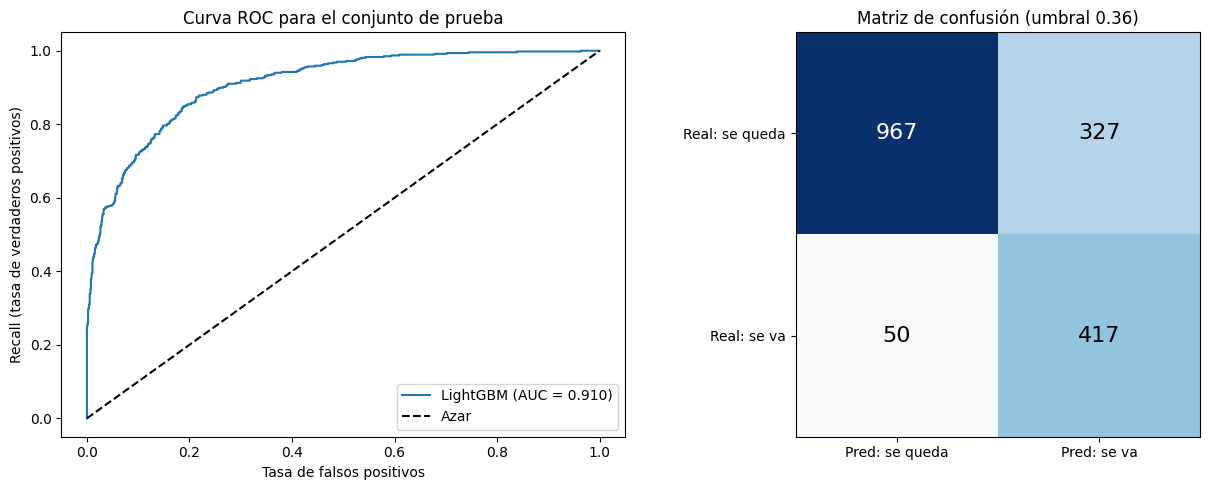

In [27]:
# Revisión datos finales
pred_final = (prob_test >= best_umbral).astype(int)

# Generación matriz de confusión
tn, fp, fn, tp = confusion_matrix(y_test, pred_final).ravel()

print(f'Clientes en el conjunto de prueba: {len(y_test)} (de ellos se van {int(y_test.sum())})')
print(f'Verdaderos positivos (se iban y se detectaron): {tp} ({tp / int(y_test.sum()) * 100 :.2f}%)')
print(f'Falsos negativos (se iban y NO se detectaron): {fn} ({fn / int(y_test.sum()) * 100 :.2f}%)')
print(f'Falsos positivos (se quedaban pero se marcaron en riesgo): {fp} ({fp / (len(y_test) - int(y_test.sum())) * 100 :.2f}%)')
print(f'Verdaderos negativos: {tn} ({tn / (len(y_test) - int(y_test.sum())) * 100 :.2f}%)')

# Curva ROC
fpr, tpr, _ = roc_curve(y_test, prob_test)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(fpr, tpr, label=f'{best_name} (AUC = {roc_auc_score(y_test, prob_test):.3f})')
axes[0].plot([0, 1], [0, 1], 'k--', label='Azar')
axes[0].set_title('Curva ROC para el conjunto de prueba')
axes[0].set_xlabel('Tasa de falsos positivos')
axes[0].set_ylabel('Recall (tasa de verdaderos positivos)')
axes[0].legend()

# Matriz de confusión
matriz = np.array([[tn, fp], [fn, tp]])
axes[1].imshow(matriz, cmap='Blues')
for i in range(2):
    for j in range(2):
        axes[1].text(j, i, matriz[i, j], ha='center', va='center', fontsize=16,
                    color='white' if matriz[i, j] > matriz.max() / 2 else 'black')
axes[1].set_title(f'Matriz de confusión (umbral {best_umbral:.2f})')
axes[1].set_xticks([0, 1]); axes[1].set_xticklabels(['Pred: se queda', 'Pred: se va'])
axes[1].set_yticks([0, 1]); axes[1].set_yticklabels(['Real: se queda', 'Real: se va'])
plt.tight_layout()
plt.show()

#### Observaciones
Se revisan los resultados en el conjunto de prueba y se genera la matriz de confusión encontrando que:
- De los *1761 clientes que se toman para probar el modelo*, **para los 467 usuarios que realmente se van, el modelo predice correctamente a 417 usuarios, un 89% de efectividad**. de los 1294 clientes que permanecen, el modelo predice que se va solo un 25.3%.
- Lo anterior muestra que el modelo tiene un buen comportamiento y que incluso trabaja con una tasa del 25% de falsos positivos, lo cual es benéfico para **Interconnect**. Este análisis aterriza el modelo en números concretos de clientes.
- La **curva ROC confirma visualmente que el modelo supera claramente al azar**.


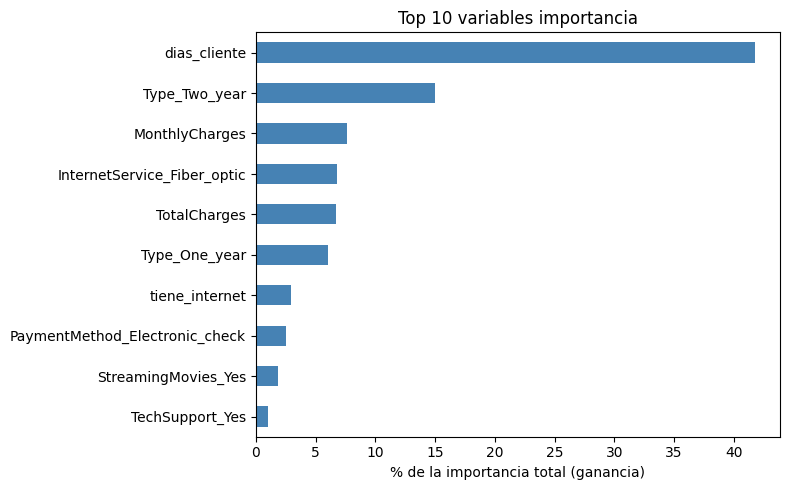

dias_cliente                      41.8
Type_Two_year                     15.0
MonthlyCharges                     7.6
InternetService_Fiber_optic        6.8
TotalCharges                       6.7
Type_One_year                      6.0
tiene_internet                     2.9
PaymentMethod_Electronic_check     2.6
StreamingMovies_Yes                1.9
TechSupport_Yes                    1.0
dtype: float64


In [31]:
# Variables críticas en el modelo (solo si el modelo es Light_GBM):
if hasattr(best_model, 'booster_'):
    relevance = pd.Series(best_model.booster_.feature_importance(importance_type='gain'),
                         index=X_train.columns)
    relevance = (relevance / relevance.sum() * 100).sort_values(ascending=False)
    relevance.head(10).iloc[::-1].plot.barh(figsize=(8, 5), color = 'steelblue')
    plt.xlabel('% de la importancia total (ganancia)')
    plt.title('Top 10 variables importancia')
    plt.tight_layout()
    plt.show()
    print(relevance.head(10).round(1))
  

#### Observaciones
Las variables de mayor importancia para predecir si un cliente permanecerá o no para **Interconnect** son:
- Antiguedad del usuario.
- Tipo de contrato (aparecen tanto el contrato a un año y a dos).
- Facturación (tanto el total que ha pagado como el cargo mensual).

Estas fueron las variables que se identificaron en la etapa de preprocesamiento que presentaban mayor indice de fuga.

**Nota: Estas variables no son incidencia directa de abandono del usuario, son variables que usa el modelo en mayor medida para realizar las predicciones**.

In [32]:
# Utilidad de negocio: si marketing contacta solo al X% de clientes con mayor riesgo, ¿qué parte de las fugas cubre?
ranking = pd.DataFrame({'prob': prob_test, 'churn': y_test.values}).sort_values('prob', ascending=False).reset_index(drop=True)
total_fugas = ranking['churn'].sum()

filas = []
for porcentaje in [10, 20, 30, 40, 50]:
    n = int(len(ranking) * porcentaje / 100)
    capturadas = ranking['churn'].iloc[:n].sum()
    filas.append({'% de clientes contactados': porcentaje, 'clientes contactados': n,
                  'fugas capturadas': int(capturadas),
                  '% de las fugas capturadas': round(capturadas / total_fugas * 100, 1)})
pd.DataFrame(filas)

,% de clientes contactados,clientes contactados,fugas capturadas,% de las fugas capturadas
0,10,176,166,35.5
1,20,352,280,60.0
2,30,528,357,76.4
3,40,704,411,88.0
4,50,880,433,92.7


#### Observaciones
En caso de que el departamento de Marketing realice campañas de fidelización con un porcentaje de los clientes que aparezcan en riesgo de cancelar su contrato ofreciendo promociones, **Contactando solo el 30% de los "clientes de alto riesgo de fuga", podrían alcanzar un 76% de las fugas**. Si contacta un 50%, alcanza hasta casi el **93% de las fugas**. Esto es una señal inequívoca de que el modelo tiene buen alcance para determinar fuga de clientes. 

## 5. Conclusiones finales
- Se ha desarrollado un sistema de predicción de abandono de clientes a partir de la información disponible de la empresa **Interconnect**.
- Se realiza un análisis preliminar a los 4 archivos disponibles con información básica de los clientes, el contrato que tienen con la empresa y los componentes básicos de sus planes de teléfono e internet.
- Adicionalmente se realiza un análisis estadístico de las variables categóricas que presenta cada juego de datos, lo que permitiría determinar posibles sesgos y desbalances en los entrenamientos. Se encuentra un desbalance en los datos que se tienen de abandono de la compañía *'churn'*.
- Se realizó un preprocesamiento de los datos, donde se pudo determinar que **un alto porcentaje de fuga obedece en usuarios con contratos mensuales, con poca antiguedad y alto costo del servicio, así como no contar con servicios de debito automático**. *Datos como la edad del usuario, o si esta casado o no, así como el tipo de facturación que recibe también influye en una menor medida*. Este dato será de utilidad al momento de realizar campañas de fidelización de usuarios.
- De la misma forma, se evalua si hay o no presencia de *data leakage* a partir de los datos que se tienen en cuenta para establecer la forma de tratar los datos.
- Se hizo una partición de datos para formar juegos de entrenamiento y prueba con relación 3:1 tratando de conservar la proporción de clientes fugados y siguiendo una codificación *OHE* para manejar variables categóricas, así como el uso de *StandardScaler* para reducir el riesgo de sesgo en los resultados.
- Se entrenan 3 modelos sin balanceo y se comparan a partir de un modelo base o *Dummy*. **Los tres modelos entrenados superan el umbral de ROC-AUC de 0.75 con un margen amplio, pero el Recall es bajo en las 3 mediciones (0.51-0.61)**, indicando que algunos clientes que se van no serían detectados por el modelo. Esto justifica aplicar técnicas de ajuste de clase. El modelo **Light-GBM** domina en este prime acercamiento.
- Luego de realizar un balanceo de clases en los 3 modelos, **el valor de Recall aumenta para los modelos de Regresión Logística y LightGBM** y **varía muy poco para Random Forest**. En este caso se castiga la precisión.
- Se realiza un **ajuste de hiperparámetros a traves de RandomizedSearchCV** evaluando diferentes hiperparámetros para cada modelo. Se observan mejoras ligeras para los modelos de *Random Forest* y *LightGBM* pero no fueron mejoras significativas y se debe considerar mas como una afinación. Se encuentra finalmente que el modelo **LightGBM presenta los mejores resultados en sus métricas**.
- A partir de todo este estudio, **Escoge el modelo LightGBM como modelo a implementar**, ya que entrega el mayor valor de **ROC-AUC en validación cruzada (0.90)**, capturando relaciones que un modelo lineal no abarca adecuadamente como **el efecto combinado de tipo de contrato, antiguedad y cargos facturados**, **con ajuste de peso para tener en cuenta la clase minoritaria y con un umbral de decisión de 0.36**.
- Se ejecuta el **modelo LightGBM** en el conjunto de prueba y se comparan los resultados con 2 umbrales: el umbral por defecto de 0.5 y el que se obtuvo en la optimización de 0.36. Se obtuvo **una métrica de ROC-AUC de 0.91**, la cual supera ampliamente el *criterio establecido de 0.75* y se comporta de manera similar al valor obtenido durante el entrenamiento, **justificando la estratificación de datos de fuga, así como el balanceo de clases y el ajuste de hiperparámetros**. Los resultados resumidos fueron:

| Métrica | Umbral 0.36 (Recomendado) | Umbral 0.50 |
| --- | --- | --- |
| **ROC-AUC** | 0.91 | 0.91 |
| **Recall** | 0.893 | 0.807 |
| **Precisión** | 0.56 | 0.64 |

- Se encuentra que tanto la **antiguedad del usuario, el tipo de contrato que tiene y la cantidad total facturada (cargo mensual o cargo total) son las principales variables que usa en modelo en su predicción**.

Con base en todo este estudio se encuentra que **El modelo satisface ampliamente las necesidades del cliente, con una métrica ROC-AUC que supera considerablemente el margen establecido**. Además: 
- **Recall (0.89)**: de cada 100 usuarios que se van a dar de baja, el modelo detecta a 89 a tiempo para ofrecerles algún tipo de promoción. 10 abandonan sin recibir la oferta.
- **Precisión (0.56)**: De cada 100 clientes que el modelo predice con riesgo de abandono, 56 se iban a ir realmente y 44 se quedarían. Estos 44 de cada 100 clientes contactados es el costo de evitar la fuga de clientes.
- **Promociones sin criterio**: Si se contacta a 50% de los usuarios seleccionados aleatoriamente sin el uso de este modelo, solo se alcanzaría al 50% de los clientes que realmente terminan su contrato. Ul usar el modelo, *esta cifra aumentaria a cerca del 92%*.
- **Presupuesto limitado**: Si el área de marketing tiene problemas de presupuesto, *se puede subir el umbral al 0.5, o solo contactar al 30% de los usuarios marcados en riesgo y de todas formas se abarcaría un porcentaje importante de clientes con verdadero riesgo (76%)*.
- **Perfil de mayor riesgo**: Clientes con *poca antiguedad, con contrato mensual y que pagan con cheque eletrónico, con internet de fibra óptica y que tienen cargos mensuales altos, son los clientes prioritarios a atender*. Una opción puede ser ofrecer planes anuales con descuento.

Pese a todo lo anterior se debe considerar que el alcance de este estudio tuvo en cuenta bajas entre octubre de 2019 y febrero de 2020, entonces la ventana será de pocos meses. Así mismo, para garantizar la confiabilidad, **este modelo se debe reentrenar periodicamente con nuevos datos**.

